# Intelligent RAG-Based Chatbot using LangChain & LLMs

## Project Overview

This project focuses on building a chatbot that reads PDF documents and answers questions based on their content.

Instead of searching through documents manually, users can ask questions in normal language and get relevant answers from the chatbot.

The system uses Retrieval-Augmented Generation (RAG) to find useful information from documents and provide answers with the help of a Large Language Model.

## Project Domain
Artificial Intelligence and Generative AI

## Technologies Used
- Python
- LangChain
- Sentence Transformers
- FAISS
- Gemini 3.5 Flash Lite (Google Gemini API)
- Streamlit

## 1. Problem Statement

Reading and searching through multiple documents can take a lot of time, especially when the documents contain large amounts of information.

Users may find it difficult to locate the exact information they need.

To solve this problem, we are developing an AI-powered document assistant that allows users to ask questions directly about selected PDF documents.

The chatbot will retrieve relevant information from the uploaded documents and generate answers based on the available content.

## Project Objectives

- Read and process selected PDF documents.
- Split document content into smaller text chunks.
- Convert text into numerical embeddings.
- Store and search document embeddings using FAISS.
- Retrieve relevant content for user questions.
- Generate answers using an LLM.
- Display answers along with their source documents.

## 2. Project Workflow

### A. Project Preparation

1. Define the problem domain and identify the type of documents the chatbot will work with.
2. Collect relevant PDF documents from reliable sources.
3. Extract text from PDF files using PyPDF.
4. Use OCR when documents contain scanned pages or image-based text.
5. Clean the extracted text by removing unnecessary spaces, repeated headers, footers and unwanted characters.
6. Maintain document metadata such as file name and page number for source tracking.

### B. Knowledge Base Creation

7. Split the extracted text into smaller chunks using LangChain text splitters.
8. Start with a chunk size of 512 tokens and an overlap of 50 tokens.
9. Generate vector embeddings using a Sentence Transformers model.
10. Store the embeddings and document chunks in a FAISS vector database.
11. Save the FAISS index locally so it can be reused without processing all documents again.

### C. Question Answering and Retrieval

12. Accept questions from users in natural language.
13. Convert each question into an embedding using the same embedding model.
14. Retrieve the top 8 most relevant document chunks from FAISS.
15. Build a prompt using the retrieved content as context.
16. Instruct the LLM to answer only using the provided context.
17. If the answer is not available in the retrieved content, the chatbot must clearly state that it does not know.
18. Generate the response using Gemini through LangChain.
19. Display the answer along with source references, including the document name and page number.

### D. Chatbot Interface

20. Develop an interactive chatbot interface using Streamlit.
21. Allow users to ask questions and view responses.
22. Display relevant source documents for each answer.
23. Handle invalid inputs, missing documents and API errors properly.

### E. Testing and Evaluation

24. Prepare at least 10 sample question-answer pairs using the collected documents.
25. Test the chatbot with different types of questions.
26. Check whether the retrieved chunks are relevant to the questions.
27. Evaluate the responses using RAGAS.
28. Measure faithfulness and answer relevancy.
29. Review the evaluation results and improve chunk size, retrieval settings and prompts where necessary.
30. Record the actual evaluation results without assuming or fabricating scores.

### F. Documentation and Final Delivery

31. Prepare a one-page document describing the selected domain and project objectives.
32. Organize the notebook and application code into separate modules.
33. Include the saved FAISS vector database for reproducibility, where practical.
34. Prepare a requirements.txt file with the required dependencies.
35. Create a README containing:
   - Project overview
   - Problem statement
   - Technologies used
   - Project architecture diagram
   - Installation and setup instructions
   - Instructions to run the chatbot
   - Sample questions and answers
   - Evaluation results
36. Verify the complete project from document ingestion to chatbot response before submission.

## Expected Project Output

A working AI Document Assistant that can read PDF documents, retrieve relevant information and answer user questions using a Large Language Model. Each response should include source references to help users verify the information.

## 3. Environment Setup

Before starting the development, we need to import the libraries required for document processing, text splitting, embeddings, vector storage and language model integration.

We will use Python with LangChain to build the RAG pipeline.

### 3.1 Import Required Libraries

Import the core libraries used for PDF processing, text splitting, embeddings, FAISS vector storage, and environment-variable management.

In [1]:
from pathlib import Path
import os
from dotenv import load_dotenv
from pypdf import PdfReader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

print("Required project libraries imported successfully.")

Required project libraries imported successfully.


C:\Users\Gowtham G\AppData\Local\Temp\ipykernel_10884\3832335057.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


### 3.2 Project Directory Setup

Create the project folders used to store source documents and the FAISS vector database.

In [2]:
PROJECT_DIR = Path.home() / "RAG_CHATBOT"

DATA_DIR = PROJECT_DIR / "data" / "documents"
VECTORSTORE_DIR = PROJECT_DIR / "vectorstore"

DATA_DIR.mkdir(parents=True, exist_ok=True)
VECTORSTORE_DIR.mkdir(parents=True, exist_ok=True)

print("Project Directory:", PROJECT_DIR)
print("Documents Folder exists:", DATA_DIR.exists())
print("Vector Store Folder exists:", VECTORSTORE_DIR.exists())

Project Directory: C:\Users\Gowtham G\RAG_CHATBOT
Documents Folder exists: True
Vector Store Folder exists: True


## 4. Document Collection

In this section, we collect relevant PDF documents related to Artificial Intelligence, Machine Learning, and Generative AI. These documents will serve as the knowledge source for our RAG-based chatbot.

**Selected Dataset:** PDF / Document Q&A (DataMites Option A)

**Source:** arXiv – Research Papers

### 4.1 Download PDF Using Python

In [3]:
import requests

pdf_url = "https://arxiv.org/pdf/2005.11401"
pdf_path = DATA_DIR / "RAG_Paper.pdf"

if pdf_path.exists() and pdf_path.stat().st_size > 0:
    print("Existing PDF found:", pdf_path.name)
else:
    response = requests.get(pdf_url, timeout=60)
    response.raise_for_status()
    pdf_path.write_bytes(response.content)
    print("PDF downloaded successfully.")

print("File:", pdf_path.name)
print("Size:", round(pdf_path.stat().st_size / 1024, 2), "KB")


Existing PDF found: RAG_Paper.pdf
File: RAG_Paper.pdf
Size: 864.57 KB


### 4.2 Verify Downloaded PDF

In [4]:
pdf_reader = PdfReader(str(pdf_path))

if len(pdf_reader.pages) == 0:
    raise ValueError("The selected PDF does not contain any pages.")

print("Total Pages:", len(pdf_reader.pages))
print("PDF Text Preview:")
print(pdf_reader.pages[0].extract_text()[:500])


Total Pages: 19
PDF Text Preview:
Retrieval-Augmented Generation for
Knowledge-Intensive NLP Tasks
Patrick Lewis†‡, Ethan Perez⋆,
Aleksandra Piktus†, Fabio Petroni†, Vladimir Karpukhin†, Naman Goyal†, Heinrich Küttler†,
Mike Lewis†, Wen-tau Yih†, Tim Rocktäschel†‡, Sebastian Riedel†‡, Douwe Kiela†
†Facebook AI Research; ‡University College London; ⋆New York University;
plewis@fb.com
Abstract
Large pre-trained language models have been shown to store factual knowledge
in their parameters, and achieve state-of-the-art results when


### 4.3 Document Collection Summary

In [5]:
documents = list(DATA_DIR.glob("*.pdf"))

print("Total PDF Documents:", len(documents))

for document in documents:
    print("Document Name:", document.name)
    print("File Size:", round(document.stat().st_size / 1024, 2), "KB")

Total PDF Documents: 1
Document Name: RAG_Paper.pdf
File Size: 864.57 KB


## 5. Document Loading & Text Extraction

### 5.1 Load PDF Using LangChain

In [6]:
from langchain_community.document_loaders import PyPDFLoader

loader = PyPDFLoader(str(pdf_path))
pages = loader.load()

print("PDF Loading Completed!")
print("Document Objects:", len(pages))
print("\nPage Metadata:")
print(pages[0].metadata)

PDF Loading Completed!
Document Objects: 19

Page Metadata:
{'producer': 'pdfTeX-1.40.21', 'creator': 'LaTeX with hyperref', 'creationdate': '2021-04-13T00:48:38+00:00', 'author': '', 'keywords': '', 'moddate': '2021-04-13T00:48:38+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.14159265-2.6-1.40.21 (TeX Live 2020) kpathsea version 6.3.2', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'C:\\Users\\Gowtham G\\RAG_CHATBOT\\data\\documents\\RAG_Paper.pdf', 'total_pages': 19, 'page': 0, 'page_label': '1'}


### 5.2 Combine Extracted Text

In [7]:
full_text = "\n\n".join(
    page.page_content for page in pages
)

print("Total Characters:", len(full_text))
print("Total Words:", len(full_text.split()))
print("\nCombined Text Preview:")
print(full_text[:1000])

Total Characters: 69056
Total Words: 9847

Combined Text Preview:
Retrieval-Augmented Generation for
Knowledge-Intensive NLP Tasks
Patrick Lewis†‡, Ethan Perez⋆,
Aleksandra Piktus†, Fabio Petroni†, Vladimir Karpukhin†, Naman Goyal†, Heinrich Küttler†,
Mike Lewis†, Wen-tau Yih†, Tim Rocktäschel†‡, Sebastian Riedel†‡, Douwe Kiela†
†Facebook AI Research; ‡University College London; ⋆New York University;
plewis@fb.com
Abstract
Large pre-trained language models have been shown to store factual knowledge
in their parameters, and achieve state-of-the-art results when ﬁne-tuned on down-
stream NLP tasks. However, their ability to access and precisely manipulate knowl-
edge is still limited, and hence on knowledge-intensive tasks, their performance
lags behind task-speciﬁc architectures. Additionally, providing provenance for their
decisions and updating their world knowledge remain open research problems. Pre-
trained models with a differentiable access mechanism to explicit non-parametric
mem

### 5.3 Text Preprocessing

In [8]:
import re

cleaned_text = re.sub(r'\s+', ' ', full_text)
cleaned_text = cleaned_text.strip()

print("Original Characters:", len(full_text))
print("Cleaned Characters:", len(cleaned_text))
print("\nCleaned Text Preview:")
print(cleaned_text[:1000])

Original Characters: 69056
Cleaned Characters: 69027

Cleaned Text Preview:
Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks Patrick Lewis†‡, Ethan Perez⋆, Aleksandra Piktus†, Fabio Petroni†, Vladimir Karpukhin†, Naman Goyal†, Heinrich Küttler†, Mike Lewis†, Wen-tau Yih†, Tim Rocktäschel†‡, Sebastian Riedel†‡, Douwe Kiela† †Facebook AI Research; ‡University College London; ⋆New York University; plewis@fb.com Abstract Large pre-trained language models have been shown to store factual knowledge in their parameters, and achieve state-of-the-art results when ﬁne-tuned on down- stream NLP tasks. However, their ability to access and precisely manipulate knowl- edge is still limited, and hence on knowledge-intensive tasks, their performance lags behind task-speciﬁc architectures. Additionally, providing provenance for their decisions and updating their world knowledge remain open research problems. Pre- trained models with a differentiable access mechanism to explicit non-para

## 6. Text Preprocessing & Chunking

### 6.1 Split Documents into Chunks

In [9]:
from langchain_core.documents import Document
import re

cleaned_pages = [
    Document(
        page_content=re.sub(r"\s+", " ", page.page_content).strip(),
        metadata=page.metadata
    )
    for page in pages
]

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=512,
    chunk_overlap=50
)

chunks = text_splitter.split_documents(cleaned_pages)

if not chunks:
    raise ValueError("No text chunks were created. Check the PDF text extraction.")

print("Total Pages:", len(pages))
print("Total Text Chunks:", len(chunks))
print("\nFirst Chunk Preview:")
print(chunks[0].page_content[:500])
print("\nChunk Metadata:")
print(chunks[0].metadata)


Total Pages: 19
Total Text Chunks: 157

First Chunk Preview:
Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks Patrick Lewis†‡, Ethan Perez⋆, Aleksandra Piktus†, Fabio Petroni†, Vladimir Karpukhin†, Naman Goyal†, Heinrich Küttler†, Mike Lewis†, Wen-tau Yih†, Tim Rocktäschel†‡, Sebastian Riedel†‡, Douwe Kiela† †Facebook AI Research; ‡University College London; ⋆New York University; plewis@fb.com Abstract Large pre-trained language models have been shown to store factual knowledge in their parameters, and achieve state-of-the-art results when

Chunk Metadata:
{'producer': 'pdfTeX-1.40.21', 'creator': 'LaTeX with hyperref', 'creationdate': '2021-04-13T00:48:38+00:00', 'author': '', 'keywords': '', 'moddate': '2021-04-13T00:48:38+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.14159265-2.6-1.40.21 (TeX Live 2020) kpathsea version 6.3.2', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'C:\\Users\\Gowtham G\\RAG_CHATBOT\\data\\documents\\RAG_Paper.pdf', 'tota

### 6.2 Analyze Chunk Distribution

In [10]:
chunk_lengths = [len(chunk.page_content) for chunk in chunks]

print("Total Chunks:", len(chunk_lengths))
print("Minimum Chunk Length:", min(chunk_lengths))
print("Maximum Chunk Length:", max(chunk_lengths))
print("Average Chunk Length:", round(sum(chunk_lengths) / len(chunk_lengths), 2))


Total Chunks: 157
Minimum Chunk Length: 42
Maximum Chunk Length: 512
Average Chunk Length: 478.39


## 7. Embedding Model Selection

### 7.1 Initialize Sentence Transformer Model

In [11]:
embedding_model = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True}
)

test_embedding = embedding_model.embed_query(
    chunks[0].page_content
)

print("Embedding Model Loaded Successfully!")
print("Embedding Dimensions:", len(test_embedding))

C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1287.16it/s]


Embedding Model Loaded Successfully!
Embedding Dimensions: 384


## 8. Vector Database Creation

### 8.1 Create FAISS Vector Store and Generate Document Embeddings

In [12]:
vectorstore = FAISS.from_documents(
    documents=chunks,
    embedding=embedding_model
)

vectorstore.save_local(str(VECTORSTORE_DIR))

print("FAISS Vector Store Created Successfully!")
print("Total Vectors:", vectorstore.index.ntotal)
print("Vector Store Saved At:", VECTORSTORE_DIR)

FAISS Vector Store Created Successfully!
Total Vectors: 157
Vector Store Saved At: C:\Users\Gowtham G\RAG_CHATBOT\vectorstore


### 8.2 Save and Reload FAISS Vector Store

In [13]:
loaded_vectorstore = FAISS.load_local(
    str(VECTORSTORE_DIR),
    embedding_model,
    allow_dangerous_deserialization=True
)

print("FAISS Vector Store Loaded Successfully!")
print("Total Vectors:", loaded_vectorstore.index.ntotal)

FAISS Vector Store Loaded Successfully!
Total Vectors: 157


## 9. Retriever Development

### 9.1 Create Document Retriever

In [14]:
retriever = loaded_vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 8}
)

print("Retriever Created Successfully!")
print("Retrieval Method: Similarity Search")
print("Top-K Documents: 8")

Retriever Created Successfully!
Retrieval Method: Similarity Search
Top-K Documents: 8


### 9.2 Test Document Retrieval

In [15]:
query = "What is Retrieval-Augmented Generation?"
retrieved_docs = retriever.invoke(query)

print("User Query:", query)
print("Retrieved Documents:", len(retrieved_docs))

for i, doc in enumerate(retrieved_docs, 1):
    page_number = doc.metadata.get("page")
    page_display = page_number + 1 if page_number is not None else "N/A"

    print(f"\n--- Retrieved Chunk {i} ---")
    print("Page:", page_display)
    print("Content:", doc.page_content[:300])

User Query: What is Retrieval-Augmented Generation?
Retrieved Documents: 8

--- Retrieved Chunk 1 ---
Page: 9
Content: generation models with access to parametric and non-parametric memory. We showed that our RAG models obtain state of the art results on open-domain QA. We found that people prefer RAG’s generation over purely parametric BART, ﬁnding RAG more factual and speciﬁc. We conducted an thorough investigatio

--- Retrieved Chunk 2 ---
Page: 1
Content: memory have so far been only investigated for extractive downstream tasks. We explore a general-purpose ﬁne-tuning recipe for retrieval-augmented generation (RAG) — models which combine pre-trained parametric and non-parametric mem- ory for language generation. We introduce RAG models where the para

--- Retrieved Chunk 3 ---
Page: 1
Content: Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks Patrick Lewis†‡, Ethan Perez⋆, Aleksandra Piktus†, Fabio Petroni†, Vladimir Karpukhin†, Naman Goyal†, Heinrich Küttler†, Mike 

## 10. LLM Integration

### 10.1 Configure Gemini API Key

In [16]:
env_path = PROJECT_DIR / ".env"

load_dotenv(env_path, override=True)
google_api_key = os.getenv("GOOGLE_API_KEY")

if not google_api_key:
    raise ValueError(
        "GOOGLE_API_KEY was not found. Add it to the .env file in the project folder."
    )

print("Google API Key loaded successfully.")

Google API Key loaded successfully.


### 10.2 Import Gemini Integration

In [17]:
print("Gemini integration imported successfully.")


Gemini integration imported successfully.


### 10.3 Configure Gemini Model

In [18]:
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0,
    google_api_key=google_api_key
)

### 10.4 Test Gemini LLM

In [19]:
print("LLM Type:", type(llm))
print("LLM Model:", llm.model)

LLM Type: <class 'langchain_google_genai.chat_models.ChatGoogleGenerativeAI'>
LLM Model: gemini-3.5-flash-lite


### 10.5 Send a Test Prompt to Gemini

Send one simple prompt directly to Gemini to confirm that the API connection works before building the RAG chain.

In [20]:
test_response = llm.invoke(
    "What is Retrieval-Augmented Generation? Explain in 3 simple points."
)

print(test_response.content)

C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'Here is Retrieval-Augmented Generation (RAG) explained in 3 simple points:\n\n1. **It searches for facts first (Retrieval):** When you ask an AI a question, it doesn\'t just rely on its memory. It first searches an external database, documents, or the internet to find the most accurate and up-to-date information.\n2. **It combines data with the AI (Augmentation):** The AI takes the information it just found and adds it to your original question to give it the necessary context. \n3. **It generates a better answer (Generation):** Finally, the AI uses this new, fact-checked information to write a smart, accurate, and personalized response, greatly reducing the chance of it making things up (hallucinating). \n\n**In short:** RAG gives an AI an "open-book test" instead of making it guess from memory.', 'extras': {'signature': 'Eo4BCosBAWkUfRPXiJK8/aBMBzSAsQCQoLjImEQWC7ib/k7NMeCKUIpY8AUuzyWE6gAFsn1s5MuTrLPvmfhWgVKek5GBlvoPABQY3cc3lmg5koiN4dfGIrluphZGVjpNlvN0haOoP2

## 11. RAG Chain Development

### 11.1 Create RAG Prompt Template

In [21]:
from langchain_core.prompts import ChatPromptTemplate

rag_prompt = ChatPromptTemplate.from_template("""
You are an AI Document Assistant.

Answer the question using only the provided context.
If the answer is not available in the context, say:
"I couldn't find this information in the provided document."

Context:
{context}

Question:
{question}

Answer:
""")

print("RAG Prompt Template Created Successfully!")

RAG Prompt Template Created Successfully!


### 11.2 Create RAG Chain

In [22]:
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

rag_chain = (
    {
        "context": retriever | format_docs,
        "question": RunnablePassthrough()
    }
    | rag_prompt
    | llm
    | StrOutputParser()
)

print("RAG Chain Created Successfully!")

RAG Chain Created Successfully!


### 11.3 Test RAG Chain

In [23]:
question = "What is Retrieval-Augmented Generation?"

answer = rag_chain.invoke(question)

print("Question:", question)
print("\nAnswer:", answer)

C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Question: What is Retrieval-Augmented Generation?

Answer: Retrieval-Augmented Generation (RAG) refers to models that combine pre-trained parametric and non-parametric memory for language generation. Specifically, RAG models use an input sequence to retrieve text documents and use them as additional context when generating a target sequence. In these models, the parametric memory is a pre-trained seq2seq model, and the non-parametric memory is a dense vector index (such as Wikipedia), which is accessed with a pre-trained neural retriever.


### 11.4 Inspect Retrieved Documents for the Neural Retriever Question

In [24]:
retrieval_question = "What does the DPR retriever do in RAG?"
test_docs = retriever.invoke(retrieval_question)

print("Question:", retrieval_question)
print("Retrieved Documents:", len(test_docs))

for i, doc in enumerate(test_docs, 1):
    print(f"\n--- Retrieved Document {i} | Page: {doc.metadata.get('page', 'N/A')} ---")
    print(doc.page_content[:700])

Question: What does the DPR retriever do in RAG?
Retrieved Documents: 8

--- Retrieved Document 1 | Page: 2 ---
can be used for sequence classiﬁcation tasks by considering the target class as a target sequence of length one, in which case RAG-Sequence and RAG-Token are equivalent. 2.2 Retriever: DPR The retrieval component pη(z|x) is based on DPR [26]. DPR follows a bi-encoder architecture: pη(z|x) ∝ exp ( d(z)⊤q(x) ) d(z) = BERTd(z), q(x) = BERTq(x) where d(z) is a dense representation of a document produced by a BERTBASE document encoder [8], and q(x) a query representation produced by a query encoder, also based

--- Retrieved Document 2 | Page: 9 ---
paper, as well as HuggingFace for their help in open-sourcing code to run RAG models. The authors would also like to thank Kyunghyun Cho and Sewon Min for productive discussions and advice. EP thanks supports from the NSF Graduate Research Fellowship. PL is supported by the FAIR PhD program. References [1] Payal Bajaj, Daniel Campos, N

### 11.5 Test Multiple RAG Questions

In [25]:
questions = [
    "What is non-parametric memory in RAG?",
    "Which retriever is used in the RAG model?",
    "How does RAG combine parametric and non-parametric memory?"
]

for i, question in enumerate(questions, 1):
    print(f"\nQuestion {i}: {question}")

    answer = rag_chain.invoke(question)
    print("Answer:", answer)
    print("-" * 70)


Question 1: What is non-parametric memory in RAG?


C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Answer: Based on the provided context, the non-parametric memory in RAG models is a dense vector index of Wikipedia, which is accessed with a pre-trained neural retriever. It does not consist of trainable parameters (and consists of 21M 728 dimensional parameters, as mentioned in the text).
----------------------------------------------------------------------

Question 2: Which retriever is used in the RAG model?


C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Answer: Based on the provided context, RAG's retriever is initialized using DPR's retriever (and the retrieval component $p_\eta(z|x)$ is based on DPR).
----------------------------------------------------------------------

Question 3: How does RAG combine parametric and non-parametric memory?


C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Answer: Based on the provided context, RAG combines parametric and non-parametric memory by using a pre-trained seq2seq model as the parametric memory and a dense vector index of Wikipedia (accessed with a pre-trained neural retriever) as the non-parametric memory for language generation.
----------------------------------------------------------------------


### 11.6 RAG Pipeline Summary

In [26]:
print("RAG PIPELINE SUMMARY")
print("-" * 50)
print("1. PDF document loaded successfully.")
print("2. Text extracted and cleaned.")
print("3. Documents split into chunks.")
print("4. Embedding model initialized.")
print("5. FAISS vector database created and saved.")
print("6. Retriever configured with k=8.")
print("7. Gemini LLM integrated.")
print("8. RAG prompt template created.")
print("9. RAG chain executed.")
print("10. Document-based questions tested.")
print("-" * 50)
print("RAG Pipeline Summary Completed.")

RAG PIPELINE SUMMARY
--------------------------------------------------
1. PDF document loaded successfully.
2. Text extracted and cleaned.
3. Documents split into chunks.
4. Embedding model initialized.
5. FAISS vector database created and saved.
6. Retriever configured with k=8.
7. Gemini LLM integrated.
8. RAG prompt template created.
9. RAG chain executed.
10. Document-based questions tested.
--------------------------------------------------
RAG Pipeline Summary Completed.


### 11.7 Verify Retrieved Source References

The retriever stores the original PDF file name and page number in each document chunk. Check these values so the application can show users where an answer was found.

In [27]:
source_question = "What is Retrieval-Augmented Generation?"
source_docs = retriever.invoke(source_question)

source_references = set()

for doc in source_docs:
    source_name = Path(doc.metadata.get("source", "Unknown")).name
    page_index = doc.metadata.get("page")
    page_number = page_index + 1 if isinstance(page_index, int) else "Unknown"
    source_references.add((source_name, page_number))

print("Source References for:", source_question)

for source_name, page_number in sorted(source_references, key=lambda item: str(item[1])):
    print(f"{source_name} — Page {page_number}")


Source References for: What is Retrieval-Augmented Generation?
RAG_Paper.pdf — Page 1
RAG_Paper.pdf — Page 12
RAG_Paper.pdf — Page 19
RAG_Paper.pdf — Page 2
RAG_Paper.pdf — Page 7
RAG_Paper.pdf — Page 9


## 12. RAG Evaluation

In this section, we evaluate the RAG pipeline using Faithfulness and Answer Relevancy. The evaluation answers are generated by the current RAG chain, and the retrieved contexts are collected from the FAISS retriever.

### 12.1 Prepare Evaluation Dataset

Prepare ten questions and reference answers based on the selected research paper. These questions are used to test the RAG pipeline and calculate Faithfulness and Answer Relevancy.


In [28]:
evaluation_data = [
    {
        "question": "What is Retrieval-Augmented Generation (RAG)?",
        "ground_truth": "RAG is a method that combines a pre-trained language generation model with retrieved external documents to support knowledge-intensive text generation."
    },
    {
        "question": "What are the two types of memory used in the RAG model?",
        "ground_truth": "RAG combines parametric memory and non-parametric memory."
    },
    {
        "question": "What is parametric memory in RAG?",
        "ground_truth": "Parametric memory is the pre-trained sequence-to-sequence language generation model."
    },
    {
        "question": "What is non-parametric memory in RAG?",
        "ground_truth": "Non-parametric memory is a dense vector index of Wikipedia that is accessed using a pre-trained neural retriever."
    },
    {
        "question": "How does RAG combine parametric and non-parametric memory?",
        "ground_truth": "The retriever finds relevant documents from the non-parametric memory, and the generator uses those documents together with its parametric memory to produce an answer."
    },
    {
        "question": "Which retriever is used to retrieve documents in the RAG paper?",
        "ground_truth": "The paper uses a pre-trained neural retriever based on Dense Passage Retrieval (DPR)."
    },
    {
        "question": "What is the role of the retrieved documents in RAG?",
        "ground_truth": "Retrieved documents provide additional non-parametric knowledge that is used as context by the generator."
    },
    {
        "question": "What is the difference between RAG-Sequence and RAG-Token?",
        "ground_truth": "RAG-Sequence uses one latent retrieved document to generate the whole output sequence, while RAG-Token can use different retrieved documents for different output tokens."
    },
    {
        "question": "How does the paper compare RAG with a purely parametric BART model?",
        "ground_truth": "The paper reports that people preferred RAG generations because they were more factual and specific than generations from purely parametric BART."
    },
    {
        "question": "Can the non-parametric memory in RAG be updated without retraining the generator?",
        "ground_truth": "Yes. The non-parametric memory can be replaced or updated to change the knowledge available to the model."
    }
]

print("Evaluation Questions:", len(evaluation_data))
for number, item in enumerate(evaluation_data, start=1):
    print(f"{number}. {item['question']}")


Evaluation Questions: 10
1. What is Retrieval-Augmented Generation (RAG)?
2. What are the two types of memory used in the RAG model?
3. What is parametric memory in RAG?
4. What is non-parametric memory in RAG?
5. How does RAG combine parametric and non-parametric memory?
6. Which retriever is used to retrieve documents in the RAG paper?
7. What is the role of the retrieved documents in RAG?
8. What is the difference between RAG-Sequence and RAG-Token?
9. How does the paper compare RAG with a purely parametric BART model?
10. Can the non-parametric memory in RAG be updated without retraining the generator?


### 12.2 Generate Answers and Collect Retrieved Contexts

For each evaluation question, generate an answer using the RAG chain and collect the retrieved document chunks. This ensures the evaluation uses actual chatbot responses rather than manually supplied answers.

In [29]:
evaluation_records = []

for number, item in enumerate(evaluation_data, start=1):
    question = item["question"].strip()

    if not question:
        raise ValueError(f"Evaluation question {number} is empty.")

    retrieved_docs = retriever.invoke(question)
    generated_answer = rag_chain.invoke(question)

    evaluation_records.append({
        "question": question,
        "answer": generated_answer,
        "contexts": [doc.page_content for doc in retrieved_docs],
        "ground_truth": item["ground_truth"]
    })

    print(f"Prepared evaluation record {number}/{len(evaluation_data)}")

if len(evaluation_records) != len(evaluation_data):
    raise ValueError("Some evaluation records were not created.")

print("\nEvaluation Records Prepared:", len(evaluation_records))
print("First Generated Answer:")
print(evaluation_records[0]["answer"])


C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Prepared evaluation record 1/10


C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Prepared evaluation record 2/10


C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Prepared evaluation record 3/10


... (10 outputs left out)

C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Prepared evaluation record 9/10


C:\Users\Gowtham G\anaconda3\envs\rag_env\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Prepared evaluation record 10/10

Evaluation Records Prepared: 10
First Generated Answer:
Based on the provided context, Retrieval-Augmented Generation (RAG) refers to models that combine pre-trained parametric and non-parametric memory for language generation. In these models, the parametric memory is a pre-trained seq2seq model, and the non-parametric memory is a dense vector index of Wikipedia that is accessed using a pre-trained neural retriever.


### 12.3 Prepare the RAGAS Dataset

Convert the evaluation records into a Hugging Face Dataset format required for the evaluation workflow.

In [30]:
from datasets import Dataset

ragas_dataset = Dataset.from_list(evaluation_records)

print("RAGAS Dataset Prepared Successfully!")
print("Total Records:", len(ragas_dataset))
print("Columns:", ragas_dataset.column_names)

if len(ragas_dataset) < 10:
    raise ValueError("The evaluation dataset must contain at least 10 questions.")


RAGAS Dataset Prepared Successfully!
Total Records: 10
Columns: ['question', 'answer', 'contexts', 'ground_truth']


### 12.4 Verify RAGAS Installation

Check the installed RAGAS version before configuring the evaluation metrics.

In [31]:
import ragas

print("RAGAS Version:", ragas.__version__)

RAGAS Version: 0.4.4


### 12.5 Configure Gemini Evaluator

Configure the Gemini model through the OpenAI-compatible Gemini endpoint for the modern RAGAS metric interface.

In [32]:
from openai import AsyncOpenAI
from ragas.llms import llm_factory

evaluator_client = AsyncOpenAI(
    api_key=google_api_key,
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/"
)

evaluator_llm = llm_factory(
    model="gemini-3.5-flash-lite",
    provider="openai",
    client=evaluator_client,
    adapter="instructor"
)

print("Evaluator Type:", type(evaluator_llm))
print("Async Support:", evaluator_llm.is_async)

Evaluator Type: <class 'ragas.llms.base.InstructorLLM'>
Async Support: True


### 12.6 Configure Evaluation Embeddings

Use the same Sentence Transformers model family for answer relevancy evaluation.

In [33]:
from ragas.embeddings import embedding_factory

evaluator_embeddings = embedding_factory(
    "huggingface",
    model="sentence-transformers/all-MiniLM-L6-v2"
)

print("RAGAS Embeddings Configured Successfully!")

C:\Users\Gowtham G\AppData\Local\Temp\ipykernel_10884\3330631983.py:3: DeprecationWarning: Importing embedding_factory from ragas.embeddings is deprecated. Import directly from ragas.embeddings.base or use modern providers: from ragas.embeddings import OpenAIEmbeddings, GoogleEmbeddings, HuggingFaceEmbeddings
  evaluator_embeddings = embedding_factory(
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1047.42it/s]


RAGAS Embeddings Configured Successfully!


### 12.7 Initialize RAGAS Metrics

Configure Faithfulness and Answer Relevancy using the Gemini evaluator and Hugging Face embeddings.

In [34]:
from ragas.metrics.collections import Faithfulness, AnswerRelevancy

faithfulness_metric = Faithfulness(
    llm=evaluator_llm
)

answer_relevancy_metric = AnswerRelevancy(
    llm=evaluator_llm,
    embeddings=evaluator_embeddings
)

print("Faithfulness Metric Ready:", faithfulness_metric.llm is not None)
print("Answer Relevancy Metric Ready:", answer_relevancy_metric.llm is not None)
print("Embeddings Ready:", answer_relevancy_metric.embeddings is not None)

Faithfulness Metric Ready: True
Answer Relevancy Metric Ready: True
Embeddings Ready: True


### 12.8 Configure Retry Handling

Add retry handling for temporary Gemini service-unavailable responses. Other errors are raised so they can be diagnosed rather than silently ignored.

In [35]:
import asyncio

async def evaluate_with_retry(metric_call, max_retries=3):
    for attempt in range(max_retries + 1):
        try:
            return await metric_call()

        except Exception as error:
            error_message = str(error).upper()
            temporary_error = any(
                marker in error_message
                for marker in ["503", "UNAVAILABLE", "429", "RESOURCE_EXHAUSTED", "TIMEOUT"]
            )

            if not temporary_error or attempt == max_retries:
                raise

            wait_time = 5 * (2 ** attempt)
            print(f"Temporary API issue. Retrying in {wait_time} seconds...")
            await asyncio.sleep(wait_time)

print("Retry handler configured successfully.")


Retry handler configured successfully.


### 12.9 Run RAGAS Evaluation

Evaluate all ten generated answers for Faithfulness and Answer Relevancy. The evaluation saves progress after each completed question, so rerunning this cell after a temporary API issue can continue without repeating completed questions.


In [36]:
import pandas as pd

progress_path = PROJECT_DIR / "ragas_evaluation_progress.csv"
current_questions = [row["question"] for row in ragas_dataset]

# Reuse completed scores when this cell is run again after a temporary API issue.
if "ragas_scores" not in globals():
    if progress_path.exists():
        previous_scores = pd.read_csv(progress_path).to_dict(orient="records")
        previous_questions = {item["question"] for item in previous_scores}

        if previous_questions.issubset(set(current_questions)):
            ragas_scores = previous_scores
        else:
            ragas_scores = []
    else:
        ragas_scores = []

completed_questions = {item["question"] for item in ragas_scores}
total_questions = len(ragas_dataset)

print("Questions in evaluation dataset:", total_questions)
print("Already completed:", len(completed_questions))

for index, row in enumerate(ragas_dataset):
    question = row["question"]

    if question in completed_questions:
        print(f"Question {index + 1} already completed. Skipping.")
        continue

    print(f"Evaluating question {index + 1}/{total_questions}...")

    faithfulness_result = await evaluate_with_retry(
        lambda row=row: faithfulness_metric.ascore(
            user_input=row["question"],
            response=row["answer"],
            retrieved_contexts=row["contexts"]
        )
    )

    relevancy_result = await evaluate_with_retry(
        lambda row=row: answer_relevancy_metric.ascore(
            user_input=row["question"],
            response=row["answer"]
        )
    )

    ragas_scores.append({
        "question": question,
        "faithfulness": float(faithfulness_result.value),
        "answer_relevancy": float(relevancy_result.value)
    })

    completed_questions.add(question)

    # Save after each question so completed work can be reused.
    pd.DataFrame(ragas_scores).to_csv(progress_path, index=False)
    print(f"Question {index + 1} completed and saved.")

if len(ragas_scores) != total_questions:
    raise RuntimeError(
        f"Evaluation is incomplete: {len(ragas_scores)} of {total_questions} questions."
    )

ragas_scores = [
    next(item for item in ragas_scores if item["question"] == question)
    for question in current_questions
]

pd.DataFrame(ragas_scores).to_csv(progress_path, index=False)

print("\nRAGAS Evaluation Completed!")
print("Total Questions Evaluated:", len(ragas_scores))
print("Progress File:", progress_path)


Questions in evaluation dataset: 10
Already completed: 10
Question 1 already completed. Skipping.
Question 2 already completed. Skipping.
Question 3 already completed. Skipping.
Question 4 already completed. Skipping.
Question 5 already completed. Skipping.
Question 6 already completed. Skipping.
Question 7 already completed. Skipping.
Question 8 already completed. Skipping.
Question 9 already completed. Skipping.
Question 10 already completed. Skipping.

RAGAS Evaluation Completed!
Total Questions Evaluated: 10
Progress File: C:\Users\Gowtham G\RAG_CHATBOT\ragas_evaluation_progress.csv


### 12.10 Review Evaluation Scores

Create a results table and calculate the average score for each metric.

In [37]:
import pandas as pd

results_df = pd.DataFrame(ragas_scores)

if results_df.empty:
    raise ValueError("No evaluation scores are available. Run Section 12.9 first.")

display(results_df)

average_faithfulness = results_df["faithfulness"].mean()
average_relevancy = results_df["answer_relevancy"].mean()

print("Average Faithfulness:", round(average_faithfulness, 4))
print("Average Answer Relevancy:", round(average_relevancy, 4))


,question,faithfulness,answer_relevancy
0,What is Retrieval-Augmented Generation (RAG)?,1.0,0.950778
1,What are the two types of memory used in the R...,1.0,1.000000
2,What is parametric memory in RAG?,0.5,0.898258
3,What is non-parametric memory in RAG?,1.0,0.958139
4,How does RAG combine parametric and non-parame...,1.0,1.000000
5,Which retriever is used to retrieve documents ...,1.0,0.651986
6,What is the role of the retrieved documents in...,1.0,0.965859
7,What is the difference between RAG-Sequence an...,1.0,0.898216
8,How does the paper compare RAG with a purely p...,1.0,0.758176
9,Can the non-parametric memory in RAG be update...,1.0,0.367617


Average Faithfulness: 0.95
Average Answer Relevancy: 0.8449


### 12.11 Visualize RAGAS Evaluation Results

Compare the Faithfulness and Answer Relevancy scores for each evaluation question.

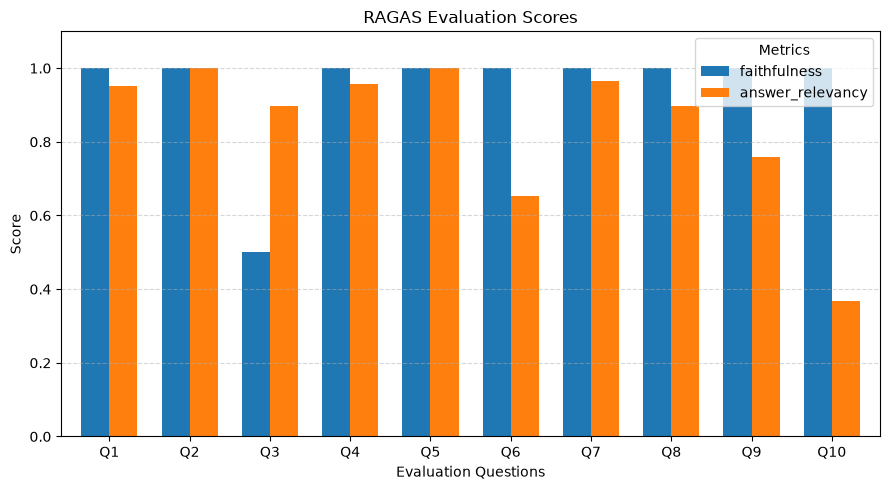

In [38]:
import matplotlib.pyplot as plt

results_df[["faithfulness", "answer_relevancy"]].plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("RAGAS Evaluation Scores")
plt.xlabel("Evaluation Questions")
plt.ylabel("Score")
plt.xticks(
    range(len(results_df)),
    [f"Q{i + 1}" for i in range(len(results_df))],
    rotation=0
)
plt.ylim(0, 1.1)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 12.12 Save Evaluation Results

Save the evaluation scores in the project folder for reporting and later reference.

In [39]:
results_path = PROJECT_DIR / "ragas_evaluation_results.csv"

results_df.to_csv(results_path, index=False)

print("Evaluation Results Saved:", results_path)

Evaluation Results Saved: C:\Users\Gowtham G\RAG_CHATBOT\ragas_evaluation_results.csv


### 12.13 Final RAGAS Evaluation Report

Display the final evaluation summary. The scores are generated when the notebook is executed; they are not fixed or assumed values.

In [40]:
print("FINAL RAGAS EVALUATION REPORT")
print("=" * 45)
print("Total Questions Evaluated:", len(results_df))
print("Average Faithfulness:", round(average_faithfulness, 4))
print("Average Answer Relevancy:", round(average_relevancy, 4))
print("=" * 45)
print("Report Status: Completed")

FINAL RAGAS EVALUATION REPORT
Total Questions Evaluated: 10
Average Faithfulness: 0.95
Average Answer Relevancy: 0.8449
Report Status: Completed


## 13. Streamlit Chatbot Application

In this section, we create a separate Streamlit application file. The notebook prepares the application, while the chatbot itself must be launched using the `streamlit run app.py` command from the project directory.

**Important:** Do not run Streamlit UI commands such as `st.chat_input()` directly in a normal Jupyter cell. They work inside the Streamlit application runtime.

### 13.1 Check Streamlit Installation

Check whether Streamlit is installed in the current Python environment.

In [41]:
import importlib.util

if importlib.util.find_spec("streamlit") is None:
    print("Streamlit is not installed. Install it with: %pip install streamlit")
else:
    print("Streamlit is already installed.")

Streamlit is already installed.


### 13.2 Create the Streamlit Application

We will build the Streamlit application in smaller parts. Each part has one responsibility, so the code is easier to understand and maintain. Run these cells from top to bottom.

The application code is written to `app.py` inside the project folder. The app will be launched separately after the notebook setup is complete.


### 13.2.1 Add Imports and Project Settings

Import the libraries required by the Streamlit interface and define the project paths. This is the starting part of `app.py`.

### 13.2.2 Load the RAG Components

Load the saved FAISS database, embedding model and Gemini model. Build the same context-only RAG chain used in the notebook.

### 13.2.3 Prepare Source References and Page Layout

Create a small helper to collect unique document and page references. Then display the app title and restore previous chat messages.

### 13.2.4 Handle User Questions

Accept a non-empty question, send it as a plain string to the RAG chain, and display the answer with its source pages.

In [42]:
app_path = PROJECT_DIR / 'app.py'

app_part_1 = r'''from pathlib import Path
import os

import streamlit as st
from dotenv import load_dotenv

from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser


PROJECT_DIR = Path(__file__).resolve().parent
VECTORSTORE_DIR = PROJECT_DIR / "vectorstore"

st.set_page_config(
    page_title="AI Document Assistant",
    page_icon="📄",
    layout="wide"
)
'''

app_path.write_text(app_part_1, encoding='utf-8')
print('Application file started:', app_path)


Application file started: C:\Users\Gowtham G\RAG_CHATBOT\app.py


In [43]:
app_part_2 = r'''@st.cache_resource
def load_rag_components():
    load_dotenv(PROJECT_DIR / ".env", override=True)
    google_api_key = os.getenv("GOOGLE_API_KEY")

    if not google_api_key:
        raise ValueError("GOOGLE_API_KEY was not found in the project .env file.")

    if not VECTORSTORE_DIR.exists():
        raise FileNotFoundError(
            f"FAISS vector store folder was not found: {VECTORSTORE_DIR}"
        )

    embedding_model = HuggingFaceEmbeddings(
        model_name="sentence-transformers/all-MiniLM-L6-v2",
        model_kwargs={"device": "cpu"},
        encode_kwargs={"normalize_embeddings": True}
    )

    vectorstore = FAISS.load_local(
        str(VECTORSTORE_DIR),
        embedding_model,
        allow_dangerous_deserialization=True
    )

    retriever = vectorstore.as_retriever(
        search_type="similarity",
        search_kwargs={"k": 8}
    )

    llm = ChatGoogleGenerativeAI(
        model="gemini-3.5-flash-lite",
        temperature=0,
        google_api_key=google_api_key
    )

    rag_prompt = ChatPromptTemplate.from_template("""
You are an AI Document Assistant.

Answer the question using only the provided context.
If the answer is not available in the context, say:
"I couldn't find this information in the provided document."

Context:
{context}

Question:
{question}

Answer:
""")

    def format_docs(docs):
        return "\\n\\n".join(doc.page_content for doc in docs)

    rag_chain = (
        {
            "context": retriever | format_docs,
            "question": RunnablePassthrough()
        }
        | rag_prompt
        | llm
        | StrOutputParser()
    )

    return rag_chain, retriever
'''

with app_path.open('a', encoding='utf-8') as app_file:
    app_file.write('\n\n' + app_part_2)

print('Application section 2 added.')


Application section 2 added.


In [44]:
app_part_3 = r'''def get_source_references(documents):
    references = []
    seen = set()

    for doc in documents:
        source_path = doc.metadata.get("source")
        source_name = Path(source_path).name if source_path else "Unknown"

        page = doc.metadata.get("page")
        page_number = page + 1 if isinstance(page, int) else "Unknown"

        reference = (source_name, page_number)

        if reference not in seen:
            seen.add(reference)
            references.append(reference)

    return references


st.title("AI Document Assistant")
st.write(
    "Ask questions about your PDF documents and receive answers "
    "with relevant source references."
)

try:
    rag_chain, retriever = load_rag_components()
except Exception as error:
    st.error("The document assistant could not be initialized.")
    st.exception(error)
    st.stop()


if "messages" not in st.session_state:
    st.session_state.messages = []


for message in st.session_state.messages:
    with st.chat_message(message["role"]):
        st.markdown(message["content"])

        if message.get("sources"):
            with st.expander("Source References"):
                for source, page in message["sources"]:
                    st.write(f"{source} — Page {page}")
'''

with app_path.open('a', encoding='utf-8') as app_file:
    app_file.write('\n\n' + app_part_3)

print('Application section 3 added.')


Application section 3 added.


In [45]:
app_part_4 = r'''user_question = st.chat_input("Ask a question about your document...")

if user_question and user_question.strip():
    st.session_state.messages.append({
        "role": "user",
        "content": user_question
    })

    with st.chat_message("user"):
        st.markdown(user_question)

    with st.chat_message("assistant"):
        with st.spinner("Searching the document and generating an answer..."):
            try:
                # The RAG chain expects a plain string question.
                response = rag_chain.invoke(user_question)

                # Retrieve matching chunks to show their source pages.
                retrieved_docs = retriever.invoke(user_question)
                source_references = get_source_references(retrieved_docs)

                st.markdown(response)

                if source_references:
                    with st.expander("Source References"):
                        for source, page in source_references:
                            st.write(f"{source} — Page {page}")

                st.session_state.messages.append({
                    "role": "assistant",
                    "content": response,
                    "sources": source_references
                })

            except Exception as error:
                st.error("Unable to process your question. Please try again.")
                st.exception(error)
'''

with app_path.open('a', encoding='utf-8') as app_file:
    app_file.write('\n\n' + app_part_4)

print('Application section 4 added.')


Application section 4 added.


### 13.2.5 Verify the Generated Application File

Check that all application parts were written successfully and that `app.py` contains valid Python syntax. This check does not launch Streamlit; we will start the app in the next section.


In [46]:
app_code_check = app_path.read_text(encoding="utf-8")
compile(app_code_check, str(app_path), "exec")

print("Application file created successfully.")
print("File:", app_path)
print("Total Lines:", len(app_code_check.splitlines()))
print("Python Syntax: Valid")


Application file created successfully.
File: C:\Users\Gowtham G\RAG_CHATBOT\app.py
Total Lines: 177
Python Syntax: Valid


### 13.3 Run the Streamlit Application

Open Anaconda Prompt or a terminal, activate the same `rag_env` environment, change to the project folder, and start the application with the following commands.

In [47]:
print("Run these commands in Anaconda Prompt:")
print()
print("conda activate rag_env")
print(f'cd /d "{PROJECT_DIR}"')
print("streamlit run app.py")

Run these commands in Anaconda Prompt:

conda activate rag_env
cd /d "C:\Users\Gowtham G\RAG_CHATBOT"
streamlit run app.py


### 13.4 Test the Chatbot

After the Streamlit page opens in your browser, test the application with questions from the PDF.

- Enter a question and confirm that an answer is displayed.
- Check that source document names and page numbers appear.
- Ask a question whose answer is not present in the document and confirm that the assistant uses the required fallback response.
- Check that the conversation history remains visible after each question.
- Confirm that invalid or empty inputs do not trigger retrieval.

**Note:** The evaluation section now prepares ten document-grounded questions. Run Section 12 from top to bottom to generate fresh scores before reporting them.

## 14. Project Documentation and Final Delivery

This section prepares the basic files needed to share and run the project. The evaluation scores in the README are taken from the results generated in Section 12; no scores are hard-coded.

### 14.1 Create requirements.txt

List the Python packages used by the notebook and Streamlit application. This file helps recreate the project environment on another computer.

In [48]:
requirements = [
    "langchain",
    "langchain-community",
    "langchain-core",
    "langchain-google-genai",
    "langchain-huggingface",
    "langchain-text-splitters",
    "faiss-cpu",
    "sentence-transformers",
    "pypdf",
    "python-dotenv",
    "requests",
    "streamlit",
    "ragas",
    "datasets",
    "openai",
    "pandas",
    "matplotlib"
]

requirements_path = PROJECT_DIR / "requirements.txt"
requirements_path.write_text("\n".join(requirements) + "\n", encoding="utf-8")

print("Requirements file created:", requirements_path)
print("Packages listed:", len(requirements))


Requirements file created: C:\Users\Gowtham G\RAG_CHATBOT\requirements.txt
Packages listed: 17


### 14.2 Create README.md

Create a project README with the project overview, architecture, setup instructions, run command, sample questions and the actual RAGAS results from this notebook.

In [49]:
readme_path = PROJECT_DIR / "README.md"

readme_content = f"""# AI Document Assistant

## Project Overview
An AI-powered document assistant that answers natural-language questions using information retrieved from PDF documents.

## Project Domain
Artificial Intelligence, Natural Language Processing and Generative AI.

## Technologies
- Python
- LangChain
- Sentence Transformers
- FAISS
- Google Gemini
- Streamlit
- RAGAS

## Architecture
PDF Document -> Text Extraction -> Text Chunking -> Embeddings -> FAISS Vector Store
-> Retriever -> Context-based Prompt -> Gemini LLM -> Answer with Source References

## Project Structure
```text
RAG_CHATBOT/
|-- app.py
|-- README.md
|-- requirements.txt
|-- .env
|-- data/
|   |-- documents/
|       |-- RAG_Paper.pdf
|-- vectorstore/
|-- RAG_Development_Complete_Cleaned.ipynb
```

## Environment Setup
1. Create or activate the `rag_env` Conda environment.
2. Install dependencies:
   `pip install -r requirements.txt`
3. Create a `.env` file in the project folder and add:
   `GOOGLE_API_KEY=your_gemini_api_key`
4. Run the notebook from Section 3 onward to prepare the PDF data and FAISS index.
5. Run the Streamlit application using:
   `streamlit run app.py`

## Sample Questions
- What is Retrieval-Augmented Generation?
- What are the two types of memory used in RAG?
- What is parametric memory in RAG?
- What is non-parametric memory in RAG?
- Which retriever is used in the RAG paper?

## RAGAS Evaluation Results
- Questions evaluated: {len(results_df)}
- Average Faithfulness: {average_faithfulness:.4f}
- Average Answer Relevancy: {average_relevancy:.4f}

These values are generated by running the evaluation cells in Section 12.

## Notes
- The chatbot is instructed to answer using retrieved document context.
- If the answer is not available in the retrieved context, it uses the configured fallback response.
- Source references display the PDF file name and page number.
- Keep the `.env` file private. Do not upload API keys to GitHub.
"""

readme_path.write_text(readme_content, encoding="utf-8")

print("README file created:", readme_path)


README file created: C:\Users\Gowtham G\RAG_CHATBOT\README.md


### 14.3 Create .gitignore

Keep private keys and temporary Python files out of version control. The FAISS index can remain in the project if it is required for the final delivery.

In [50]:
gitignore_content = """# Secrets
.env

# Python cache
__pycache__/
*.py[cod]

# Jupyter checkpoints
.ipynb_checkpoints/

# Virtual environments
.venv/
venv/
"""

gitignore_path = PROJECT_DIR / ".gitignore"
gitignore_path.write_text(gitignore_content, encoding="utf-8")

print(".gitignore created:", gitignore_path)


.gitignore created: C:\Users\Gowtham G\RAG_CHATBOT\.gitignore


### 14.4 Final Project Checklist

Use this checklist after running the notebook. Items that require a real Streamlit run or manual review are left as checks for the project owner; the notebook will not mark them as completed automatically.

In [51]:
final_checks = {
    "PDF file exists": pdf_path.exists(),
    "PDF pages loaded": len(pages) > 0,
    "Text chunks created": len(chunks) > 0,
    "Embedding model initialized": len(test_embedding) == 384,
    "FAISS index created": loaded_vectorstore.index.ntotal > 0,
    "Retriever configured with top-k 8": retriever.search_kwargs.get("k") == 8,
    "RAG chain created": rag_chain is not None,
    "Ten evaluation records prepared": len(evaluation_records) >= 10,
    "Ten evaluation results available": len(results_df) >= 10,
    "Streamlit app file created": app_path.exists(),
    "Requirements file created": requirements_path.exists(),
    "README file created": readme_path.exists()
}

for task, completed in final_checks.items():
    status = "READY" if completed else "PENDING"
    print(f"{status:7} - {task}")

print("\nManual checks still required:")
print("1. Launch Streamlit and test the chatbot in a browser.")
print("2. Confirm answers and source page references.")
print("3. Test a question whose answer is not in the PDF.")
print("4. Confirm .env is not committed or shared.")
print("5. Review README details before submission.")


READY   - PDF file exists
READY   - PDF pages loaded
READY   - Text chunks created
READY   - Embedding model initialized
READY   - FAISS index created
READY   - Retriever configured with top-k 8
READY   - RAG chain created
READY   - Ten evaluation records prepared
READY   - Ten evaluation results available
READY   - Streamlit app file created
READY   - Requirements file created
READY   - README file created

Manual checks still required:
1. Launch Streamlit and test the chatbot in a browser.
2. Confirm answers and source page references.
3. Test a question whose answer is not in the PDF.
4. Confirm .env is not committed or shared.
5. Review README details before submission.
